# Molecular dynamics of Lennard-Jones particles
### A guided programming case study

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 13 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/13_Molecular_Dynamics_Introduction.ipynb)

This case study is intended for first-year undergraduate students.

In molecular dynamics (MD), a computer repeatedly calculates the forces on particles and uses Newton's laws to predict their next positions and velocities. We will build a small, deliberately simplified model and use its output to practise elementary data analysis.

No previous knowledge of MD or molecular interactions is assumed. Basic algebra, vectors, Newton's second law, and introductory Python are sufficient. Run cells **from top to bottom** using *Run All*. The notebook uses only NumPy and Matplotlib. On a local machine, install them with `python -m pip install numpy matplotlib` if necessary. A fresh run normally takes a few seconds.


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 5, Efficiency |
| **Time** | about 35 min (about 70 min with experiments) |
| **Before this** | Newton's second law; loops, functions and NumPy arrays (notebook 05). |
| **Essential** | All sections; the notebook is short. |
| **Optional on a first reading** | — |
| **Next** | 14, the same simulation, made efficient. |

**You have understood this notebook if you can, without looking back:**

1. Explain how the Lennard-Jones potential gives the force between two particles, and why they repel at short distance.
2. Apply the periodic box and the minimum-image rule to a pair separation.
3. Trace one velocity Verlet step line by line: half-kick, drift, new forces, half-kick.
4. Explain why the temperature moves away from its starting value while the total energy stays nearly constant.
5. Show that the same seed reproduces a run exactly, and that the total force is zero.

**Not expected of you:** The cutoff shift, pressure or structure: those are in the advanced notebook.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## What you will learn

By the end, you should be able to explain (1) how a pair interaction produces a force, (2) why the force on one particle has an equal and opposite partner, (3) how a small time step advances Newton's equations, and (4) how temperature and energy are calculated from the resulting numerical data.

This also revisits the programming ideas used in class:

| Programming idea | Use in this notebook |
|:--|:--|
| Variables and numerical types | Store particle number, box length, time step and energies. |
| Lists and indices | Record successive measurements; access particle `i` and particle `j`. |
| Loops | Visit each distinct pair; advance the simulation through time. |
| `if` conditions | Detect an impossible close contact and select saved snapshots. |
| Functions | Give one job to each calculation and reuse it. |
| Dictionaries | Return a named collection of simulation results. |
| Random numbers | Generate initial velocities with a reproducible seed. |

**New tool: NumPy arrays.** An array holds many numbers, much like a nested list, and supports vector arithmetic. For example, `positions[i]` gives the two coordinates of particle `i`. We use arrays for arithmetic and ordinary lists for the time history.


## 1. From Newton's law to a particle model

For particle $i$, Newton's second law is $m\mathbf a_i=\mathbf F_i$. A molecular model supplies a rule for the force $\mathbf F_i$. We use the Lennard-Jones (LJ) pair potential

$$U(r)=4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right],$$

where $r$ is the distance between two particles. The first term represents strong short-range repulsion; the second represents attraction at somewhat larger separation. $\sigma$ is a length scale and $\varepsilon$ an energy scale. The minimum occurs at $r=2^{1/6}\sigma\approx1.122\sigma$, where $U=-\varepsilon$. A particle is **not** a hard sphere of diameter $\sigma$.

We choose **reduced units**: $m=\sigma=\varepsilon=k_\mathrm B=1$. Thus distance is measured in units of $\sigma$, energy in units of $\varepsilon$, time in units of $\sigma\sqrt{m/\varepsilon}$, and temperature is $T^*=k_\mathrm BT/\varepsilon$. Our printed temperature is dimensionless; it is **not kelvin**. No particular real substance has been assigned to the particles.


In [1]:
# Import math for square roots of plain numbers.
import math
# Import statistics for the mean and sample standard deviation of a list.
import statistics
# Import NumPy for arrays of positions, velocities and forces.
import numpy as np
# Import Matplotlib's pyplot interface for figures.
import matplotlib.pyplot as plt

# Print the NumPy version so results can be compared across computers.
print('NumPy version:', np.__version__)
# Print the Matplotlib version for the same reason.
print('Matplotlib version:', plt.matplotlib.__version__)
# The LJ energy is lowest at r* = 2^(1/6) ≈ 1.122; print it as a reference value.
print('LJ potential minimum at r* =', round(2**(1/6), 3))


NumPy version: 2.5.3
Matplotlib version: 3.11.2
LJ potential minimum at r* = 1.122


The next graph makes the force rule tangible. Repulsion dominates at small $r$; at large $r$, both the attraction and the force become weak. The vertical lines mark $r=\sigma$ and the minimum of $U$.


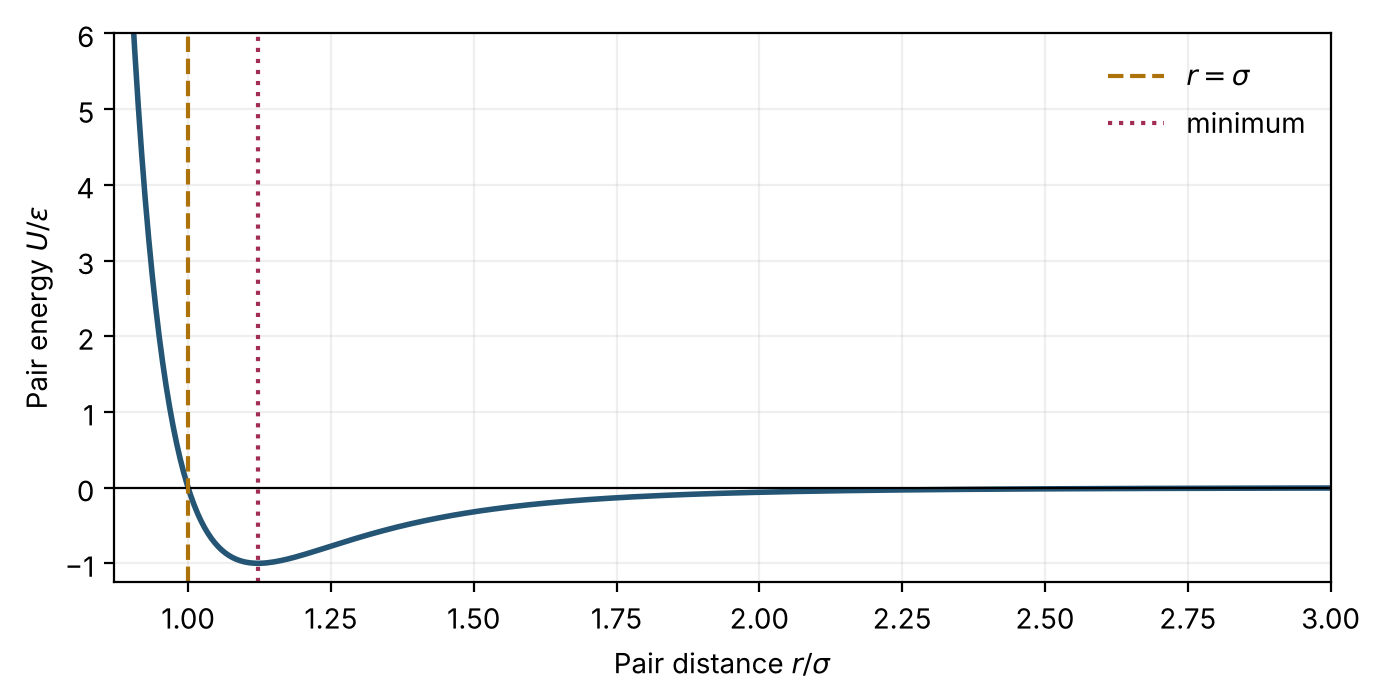

In [2]:
# 350 evenly spaced pair distances from 0.87 to 3.0 (in units of sigma).
distance = np.linspace(0.87, 3.0, 350)
# Compute (1/r)^6 once and reuse it for both terms.
inverse_sixth = (1.0 / distance)**6
# LJ pair energy U = 4[(1/r)^12 - (1/r)^6]; note (1/r)^12 = ((1/r)^6)^2.
pair_potential = 4.0 * (inverse_sixth**2 - inverse_sixth)

# Create one figure with one set of axes.
fig, ax = plt.subplots(figsize=(7, 3.6))
# Plot U(r) as a smooth curve.
ax.plot(distance, pair_potential, color='#245575', linewidth=2)
# Horizontal line at U = 0 for reference.
ax.axhline(0, color='black', linewidth=0.8)
# Vertical dashed line at r = sigma, where U crosses zero.
ax.axvline(1.0, color='#ae720b', linestyle='--', label=r'$r=\sigma$')
# Vertical dotted line at the minimum, r = 2^(1/6).
ax.axvline(2**(1/6), color='#a12c56', linestyle=':', label='minimum')
# Set axis ranges and labels (LaTeX between $ signs is rendered as mathematics).
ax.set(xlim=(0.87, 3.0), ylim=(-1.25, 6), xlabel=r'Pair distance $r/\sigma$',
       ylabel=r'Pair energy $U/\varepsilon$')
# Show the legend without a box around it.
ax.legend(frameon=False)
# Add a faint grid to make values easier to read.
ax.grid(alpha=0.2)
# Adjust spacing so labels are not cut off.
fig.tight_layout()
# Display the figure.
plt.show()


### From energy to force

Force is the negative slope of potential energy. If $\mathbf d=\mathbf r_i-\mathbf r_j$ and $r=|\mathbf d|$, the force **on $i$ due to $j$** is

$$\mathbf F_{ij}=24\left(\frac{2}{r^{12}}-\frac{1}{r^6}\right)\frac{\mathbf d}{r^2}.$$

The reduced-unit constants are all one. At a short distance the coefficient is positive and the particles push apart; sufficiently far apart it is negative and they pull together. Newton's third law gives $\mathbf F_{ji}=-\mathbf F_{ij}$. We calculate each pair only once, then add its force to one particle and subtract it from the other.

**Check before continuing.** At $r=1$, the potential is zero, but is the force zero? Use the force formula: it is repulsive. Zero potential and zero force are different statements.


## 2. The box and its periodic boundary

We place 16 particles on a $4\times4$ lattice in a **two-dimensional** square box. A particle leaving the right edge re-enters at the left edge; the same rule applies vertically. This is a computational tiling device, not a physical wall. The number density is $\rho^*=N/L^2=0.45$, so the box length is $L=\sqrt{N/0.45}$.

For a pair, we choose the nearest periodic copy. For instance, positions $x=0.2$ and $x=5.8$ in a box of length 6 are separated by $0.4$, not $5.6$. In code, `delta -= L * np.rint(delta / L)` applies this **minimum-image convention** to both coordinates. We include pairs only if $r<r_c=2.5\sigma$; here $r_c<L/2$, so that rule is consistent with the nearest-image calculation. At the cutoff we subtract the small value $U(r_c)$ from each included pair energy, making the potential energy continuous as a pair enters or leaves the interaction range. The force is set to zero beyond the cutoff and remains discontinuous at $r_c$. This is a teaching approximation whose effect we examine through the energy check.


In [3]:
# Particles per row (and per column) of the starting square lattice.
grid_side = 4
particle_count = grid_side**2       # an integer variable
number_density = 0.45              # particles per reduced area, not volume
# Area L² = N / density, so the box side is L = sqrt(N / density).
box_length = math.sqrt(particle_count / number_density)
# Distance between neighbouring lattice points.
grid_spacing = box_length / grid_side

# Each inner list is one [x, y] position. Conversion makes a (16, 2) array.
starting_positions = np.array([
    [(ix + 0.5) * grid_spacing, (iy + 0.5) * grid_spacing]
    for iy in range(grid_side) for ix in range(grid_side)
], dtype=float)

# Example separation of two particles near opposite walls of a box of side 6.
delta_example = np.array([0.2 - 5.8, 0.0])
# Minimum image: subtract whole box lengths so the nearest periodic copy is used.
nearest_example = delta_example - 6.0 * np.rint(delta_example / 6.0)
# Print the particle count, box length and lattice spacing.
print(f'N = {particle_count}; L = {box_length:.3f}; spacing = {grid_spacing:.3f}')
# The array has 16 rows (particles) and 2 columns (x, y).
print('Array shape:', starting_positions.shape)
# Row 0 holds the first particle's [x, y].
print('First particle:', starting_positions[0])
# -5.6 becomes +0.4: the two particles are actually close across the wall.
print('Minimum-image separation example:', nearest_example)


N = 16; L = 5.963; spacing = 1.491
Array shape: (16, 2)
First particle: [0.74535599 0.74535599]
Minimum-image separation example: [0.4 0. ]


The starting lattice prevents particles from overlapping. It is an artificial initial condition, not evidence of a crystalline phase. Velocities are random and the particles will move away from these initial sites.


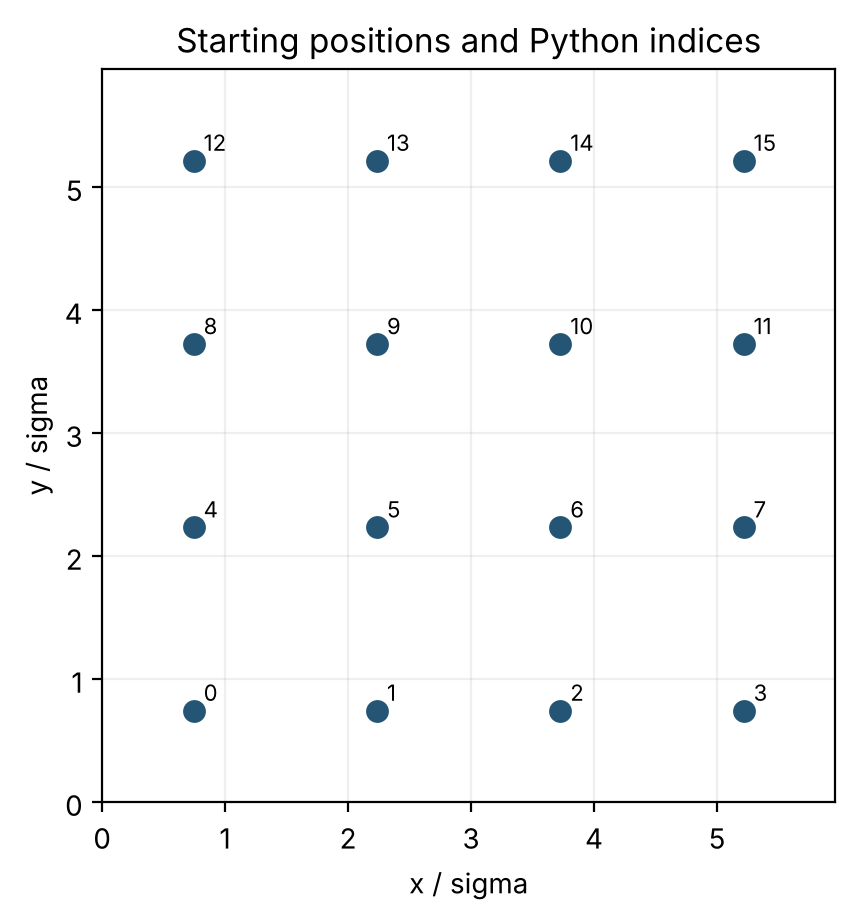

In [4]:
# Create a square figure.
fig, ax = plt.subplots(figsize=(4.7, 4.7))
# Draw every particle as a dot: column 0 holds x, column 1 holds y.
ax.scatter(starting_positions[:, 0], starting_positions[:, 1], s=85,
           color='#245575', edgecolor='white')
# enumerate gives each particle's index together with its (x, y).
for index, (x, y) in enumerate(starting_positions):
    # Write the index next to the dot, slightly offset so it does not cover it.
    ax.text(x + 0.08, y + 0.08, str(index), fontsize=8)
# Show exactly one box and label the axes.
ax.set(xlim=(0, box_length), ylim=(0, box_length), xlabel='x / sigma',
       ylabel='y / sigma', title='Starting positions and Python indices')
# Equal scaling so the square box looks square.
ax.set_aspect('equal')
# Faint grid.
ax.grid(alpha=0.2)
# Tidy the layout.
fig.tight_layout()
# Display the figure.
plt.show()


## 3. Calculate all pair forces

The outer loop visits particle indices `i = 0, ..., N-2`. The inner loop begins at `i + 1`, so it never compares a particle with itself or counts a pair twice. `displacement` is a two-component array, and `distance_squared` is its dot product with itself.

The function returns **both** the force array and the total potential energy. The potential is accumulated once per interacting pair. A very small separation raises an error because the $r^{-12}$ interaction would otherwise produce an enormous number; this is a diagnostic, not an altered LJ potential. A second `if` skips pairs at or beyond the cutoff. For each included pair the code adds $U(r)-U(r_c)$, while retaining the LJ force shown above.


In [5]:
# Define the function that computes all forces and the total potential energy.
def forces_and_potential(positions, length):
    # Return force on each particle and total LJ pair potential energy.
    n = len(positions)
    # Start every force at zero; same shape as positions, (N, 2).
    forces = np.zeros_like(positions)
    # Running total of the potential energy.
    potential = 0.0
    # Pairs farther apart than 2.5 sigma are ignored.
    cutoff = 2.5
    # Compare squared distances so no square root is needed.
    cutoff_squared = cutoff**2
    # (1/r_c)^6, needed for the energy shift.
    cutoff_inverse_sixth = (1.0 / cutoff)**6
    # U(r_c): subtracted below so the pair energy is exactly zero at the cutoff.
    potential_at_cutoff = 4.0 * (cutoff_inverse_sixth**2 - cutoff_inverse_sixth)

    # Particle i runs from 0 to n-2 ...
    for i in range(n - 1):
        # ... and partner j from i+1 to n-1, so each pair is visited once.
        for j in range(i + 1, n):
            # Separation vector from j to i.
            displacement = positions[i] - positions[j]
            # Minimum-image convention for the periodic box.
            displacement -= length * np.rint(displacement / length)
            # r² = dx² + dy².
            distance_squared = np.dot(displacement, displacement)

            # r < 0.3 means the particles practically overlap: stop with an error.
            if distance_squared < 0.09:
                # Raise an exception with a clear message instead of returning nonsense.
                raise ValueError('Particles are too close; inspect the setup.')
            # Pairs beyond the cutoff contribute nothing ...
            if distance_squared >= cutoff_squared:
                continue  # no interaction outside the range

            # 1/r², computed once per pair.
            inverse_r2 = 1.0 / distance_squared
            # 1/r⁶ = (1/r²)³.
            inverse_r6 = inverse_r2**3
            # 1/r¹² = (1/r⁶)².
            inverse_r12 = inverse_r6**2
            # Add this pair's shifted energy to the total.
            potential += 4.0 * (inverse_r12 - inverse_r6) - potential_at_cutoff

            # Force on i from j: 24[2(1/r)^12 - (1/r)^6] (1/r²) times the separation vector.
            pair_force = (24.0 * (2.0 * inverse_r12 - inverse_r6)
                          * inverse_r2 * displacement)
            # Add it to particle i ...
            forces[i] += pair_force
            forces[j] -= pair_force       # equal and opposite

    # Return both results as a tuple.
    return forces, potential

# Compute forces and energy for the starting lattice.
initial_forces, initial_potential = forces_and_potential(
    starting_positions, box_length)
# Print the starting potential energy.
print('Initial potential energy:', round(initial_potential, 4))
# The forces should cancel in total (Newton's third law); round away round-off noise.
print('Net force (x and y):', np.round(initial_forces.sum(axis=0), 12))


Initial potential energy: -10.9982
Net force (x and y): [0. 0.]


The nearly zero net force is a useful check of the equal-and-opposite updates. On the symmetric initial lattice, each individual net force is also small; this special symmetry does not persist as particles move.

For a direct test of the force calculation, take two particles separated by $r=1$ and place them in a box much wider than their separation. In reduced units, the force on the particle to the right should be $+24$ in the $x$ direction. The pair **energy** is not zero here: subtracting $U(r_c)$ changed its reference value. The following cell verifies the force without relying on the full 16-particle simulation.


In [6]:
# Two particles one unit apart along x.
two_positions = np.array([[2.0, 2.0], [1.0, 2.0]])
# A large box (10) so periodic copies do not interfere.
two_forces, two_potential = forces_and_potential(two_positions, length=10.0)
# Energy at r = 1 (not zero, because of the cutoff shift).
print('Pair energy at r = 1:', two_potential)
# Expected +24 in x: the particles repel.
print('Force on right particle:', two_forces[0])
# Expected -24 in x: equal and opposite.
print('Force on left particle: ', two_forces[1])
# Check the right particle's force against the hand calculation.
assert np.allclose(two_forces[0], [24.0, 0.0])
# Check that the two forces sum to zero.
assert np.allclose(two_forces.sum(axis=0), [0.0, 0.0])

# Two particles exactly 2.5 apart, at the cutoff.
cutoff_positions = np.array([[3.5, 2.0], [1.0, 2.0]])
# Compute their forces and energy.
cutoff_forces, cutoff_potential = forces_and_potential(cutoff_positions, 10.0)
# Both should be zero at the cutoff.
print('Exactly at cutoff: energy =', cutoff_potential,
      '; force norm =', np.linalg.norm(cutoff_forces))
# The shifted energy is exactly zero at the cutoff ...
assert cutoff_potential == 0.0
# ... and so is the force, because the pair is skipped.
assert np.allclose(cutoff_forces, 0.0)


Pair energy at r = 1: 0.016316891136000006
Force on right particle: [24.  0.]
Force on left particle:  [-24.   0.]
Exactly at cutoff: energy = 0.0 ; force norm = 0.0


## 4. Initial velocities and kinetic temperature

We draw the $x$ and $y$ velocity components from a normal random-number generator. The **seed** makes this starting draw reproducible. We then subtract the mean velocity, making the total momentum zero for equal masses, and rescale to an initial reduced kinetic temperature $T_0^*=0.90$.

With mass and $k_\mathrm B$ equal to one, $K=\tfrac12\sum_i(v_{ix}^2+v_{iy}^2)$. We remove two centre-of-mass velocity components, leaving $f=2N-2$ independent velocity degrees of freedom. The instantaneous kinetic-temperature estimate is therefore

$$T^*_{\mathrm{kin}}=\frac{2K}{2N-2}=\frac{K}{N-1}.$$

It may fluctuate during the run. This is an isolated, approximately constant-energy simulation with **no thermostat**; setting the initial value does not hold subsequent temperatures fixed. The temperature formula is for this *two-dimensional* setup, not a three-dimensional one.


In [7]:
# Define a function for the total kinetic energy.
def kinetic_energy(velocities):
    # Total kinetic energy when all particle masses are one.
    return 0.5 * float(np.sum(velocities**2))


# Define a function for the kinetic temperature.
def kinetic_temperature(velocities):
    # Two-dimensional kinetic temperature after zero COM momentum.
    n = len(velocities)
    # 2 velocity components per particle, minus 2 fixed by zero total momentum.
    degrees_of_freedom = 2 * n - 2
    # Equipartition: T* = 2K / (degrees of freedom).
    return 2.0 * kinetic_energy(velocities) / degrees_of_freedom


# Define a function that creates random starting velocities at a chosen temperature.
def make_initial_velocities(seed, target_temperature, n):
    # A seeded random generator, so the same seed gives the same velocities.
    rng = np.random.default_rng(seed)
    # Draw each velocity component from a standard normal distribution.
    velocities = rng.normal(loc=0.0, scale=1.0, size=(n, 2))
    velocities -= velocities.mean(axis=0)  # zero centre-of-mass velocity
    # Temperature of these random velocities.
    current_temperature = kinetic_temperature(velocities)
    # Rescale every velocity so the temperature equals the target exactly.
    velocities *= math.sqrt(target_temperature / current_temperature)
    # Return the (n, 2) velocity array.
    return velocities

# The seed that fixes the random velocities.
random_seed = 2026
# Target starting temperature in reduced units.
initial_temperature = 0.90
# Create the starting velocities.
starting_velocities = make_initial_velocities(
    random_seed, initial_temperature, particle_count)
# Print the starting kinetic energy.
print('Initial K:', round(kinetic_energy(starting_velocities), 4))
# Should print 0.9, the target.
print('Initial T*:', round(kinetic_temperature(starting_velocities), 4))
# Should print [0, 0]: no net drift.
print('Mean velocity:', np.round(starting_velocities.mean(axis=0), 12))


Initial K: 13.5
Initial T*: 0.9
Mean velocity: [-0. -0.]


## 5. Move the particles with velocity Verlet

For the first half-step in velocity and the full position step, Newton's law gives

$$\mathbf v_{n+1/2}=\mathbf v_n+\frac{\Delta t}{2}\mathbf F(\mathbf r_n),\qquad
\mathbf r_{n+1}=\mathbf r_n+\Delta t\,\mathbf v_{n+1/2}.$$

After recomputing the force at the new positions, finish the velocity step:

$$\mathbf v_{n+1}=\mathbf v_{n+1/2}+\frac{\Delta t}{2}\mathbf F(\mathbf r_{n+1}).$$

Mass is one in these equations. `positions % length` wraps coordinates into the box; the unwrapped trajectory would require a separate counter. The `for` loop advances time. Each measurement is appended to a Python list; at the end we convert histories to arrays for plotting.


In [8]:
# Define the simulation: velocity Verlet integration for n_steps steps.
def run_md(seed=2026, time_step=0.004, n_steps=800):
    # Run a small 2D LJ simulation; return a dictionary of histories.
    positions = starting_positions.copy()
    # Fresh random velocities for this seed.
    velocities = make_initial_velocities(seed, initial_temperature,
                                         particle_count)
    # Forces and energy at time 0.
    forces, potential = forces_and_potential(positions, box_length)

    # List of recorded times.
    times = [0.0]
    # List of kinetic energies, starting with K(0).
    kinetic_history = [kinetic_energy(velocities)]
    # List of potential energies.
    potential_history = [potential]
    # List of kinetic temperatures.
    temperature_history = [kinetic_temperature(velocities)]
    # Dictionary of saved configurations, keyed by step number.
    snapshots = {0: positions.copy()}

    # Advance one time step per loop pass.
    for step in range(1, n_steps + 1):
        # Half-kick: v(t + dt/2) = v(t) + (dt/2) F(t).
        halfway_velocity = velocities + 0.5 * time_step * forces
        # Drift: r(t + dt) = r(t) + dt v(t + dt/2), wrapped into the box with %.
        positions = (positions + time_step * halfway_velocity) % box_length
        # Forces and energy at the new positions.
        new_forces, potential = forces_and_potential(positions, box_length)
        # Second half-kick: v(t + dt) = v(t + dt/2) + (dt/2) F(t + dt).
        velocities = halfway_velocity + 0.5 * time_step * new_forces
        # The new forces become the current forces for the next step.
        forces = new_forces

        # Record the time.
        times.append(step * time_step)
        # Record the kinetic energy.
        kinetic_history.append(kinetic_energy(velocities))
        # Record the potential energy.
        potential_history.append(potential)
        # Record the temperature.
        temperature_history.append(kinetic_temperature(velocities))

        # At the midpoint and at the final step ...
        if step in (n_steps // 2, n_steps):
            # ... save a copy of the positions (a copy, so later steps do not change it).
            snapshots[step] = positions.copy()

    # Convert the lists to arrays so they can be added element by element.
    kinetic = np.array(kinetic_history)
    # Same for the potential energies.
    potential = np.array(potential_history)
    # Return all results in one dictionary with descriptive keys.
    return {
        'time': np.array(times),
        'kinetic': kinetic,
        'potential': potential,
        'total': kinetic + potential,
        'temperature': np.array(temperature_history),
        'snapshots': snapshots,
        'seed': seed,
        'time_step': time_step,
        'n_steps': n_steps,
    }

# Run the default simulation: 800 steps with dt = 0.004.
results = run_md()
# 801 samples: the initial state plus one per step.
print('Recorded samples:', len(results['time']))
# Total energy at the start.
print('Initial E*:', round(results['total'][0], 4))
# Total energy at the end: it should be nearly the same.
print('Final E*:  ', round(results['total'][-1], 4))


Recorded samples: 801
Initial E*: 2.5018
Final E*:   2.505


## 6. Inspect the motion and numerical histories

Compare the starting lattice with the final arrangement. These are only two snapshots; the particles moved between them and some wrapped through a boundary. A still image cannot tell you the complete trajectory.


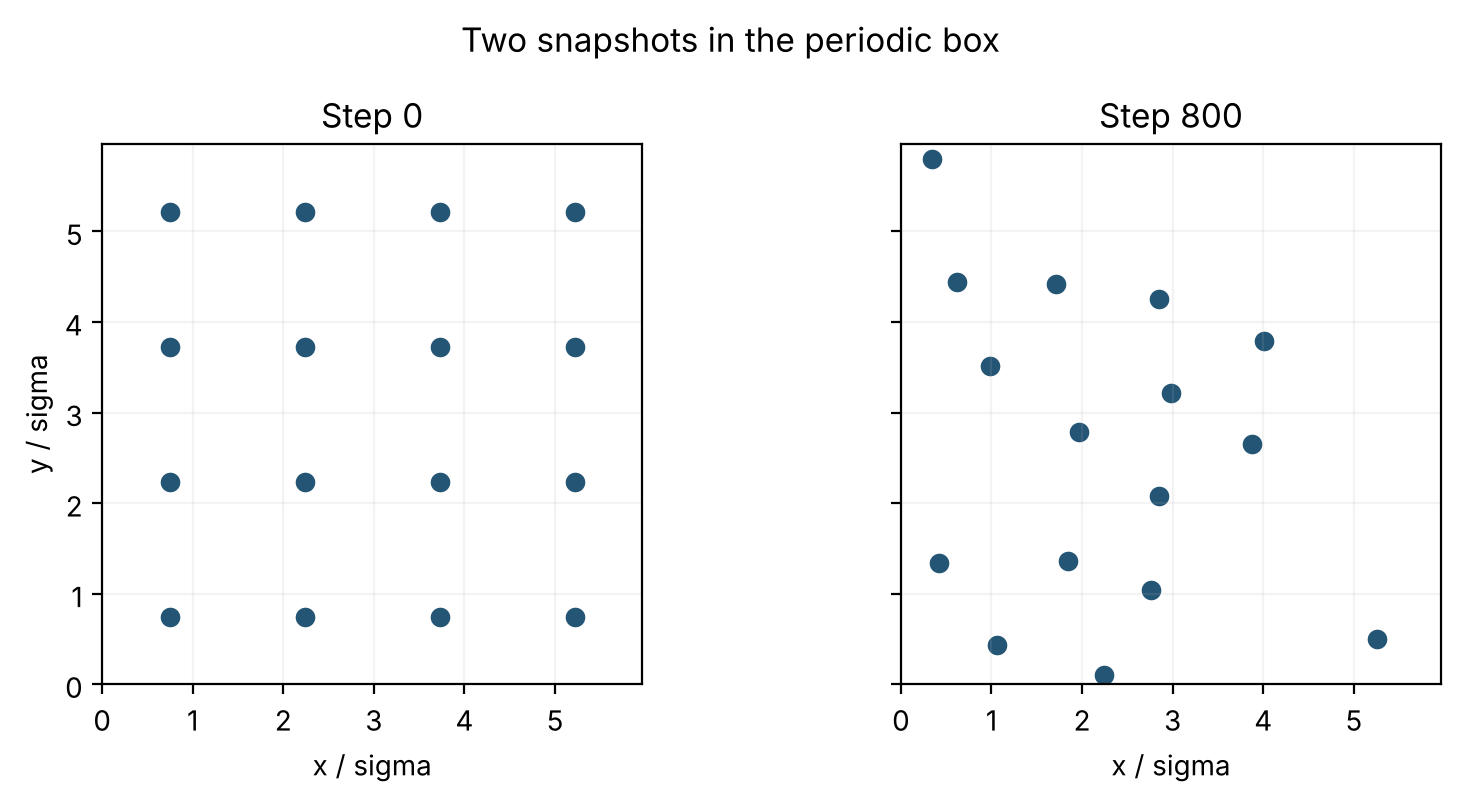

In [9]:
# Two side-by-side panels with shared axes.
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.0), sharex=True, sharey=True)
# Left panel: step 0; right panel: the final step.
for ax, step in zip(axes, (0, results['n_steps'])):
    # The saved (16, 2) positions for this step.
    points = results['snapshots'][step]
    # Draw the particles.
    ax.scatter(points[:, 0], points[:, 1], s=65, color='#245575',
               edgecolor='white')
    # Show the whole box, with a title and x-label.
    ax.set(xlim=(0, box_length), ylim=(0, box_length),
           title=f'Step {step}', xlabel='x / sigma')
    # Equal scaling.
    ax.set_aspect('equal')
    # Faint grid.
    ax.grid(alpha=0.15)
# Only the left panel needs a y-label.
axes[0].set_ylabel('y / sigma')
# One title over both panels.
fig.suptitle('Two snapshots in the periodic box')
# Tidy the layout.
fig.tight_layout()
# Display the figure.
plt.show()


The mechanical energy is $E=K+U$. In an ideal isolated system, total energy is constant even though kinetic and potential energy exchange. Numerical integration introduces errors, so we monitor $E(t)$ rather than assuming conservation. The temperature curve can fluctuate while total energy remains nearly constant.


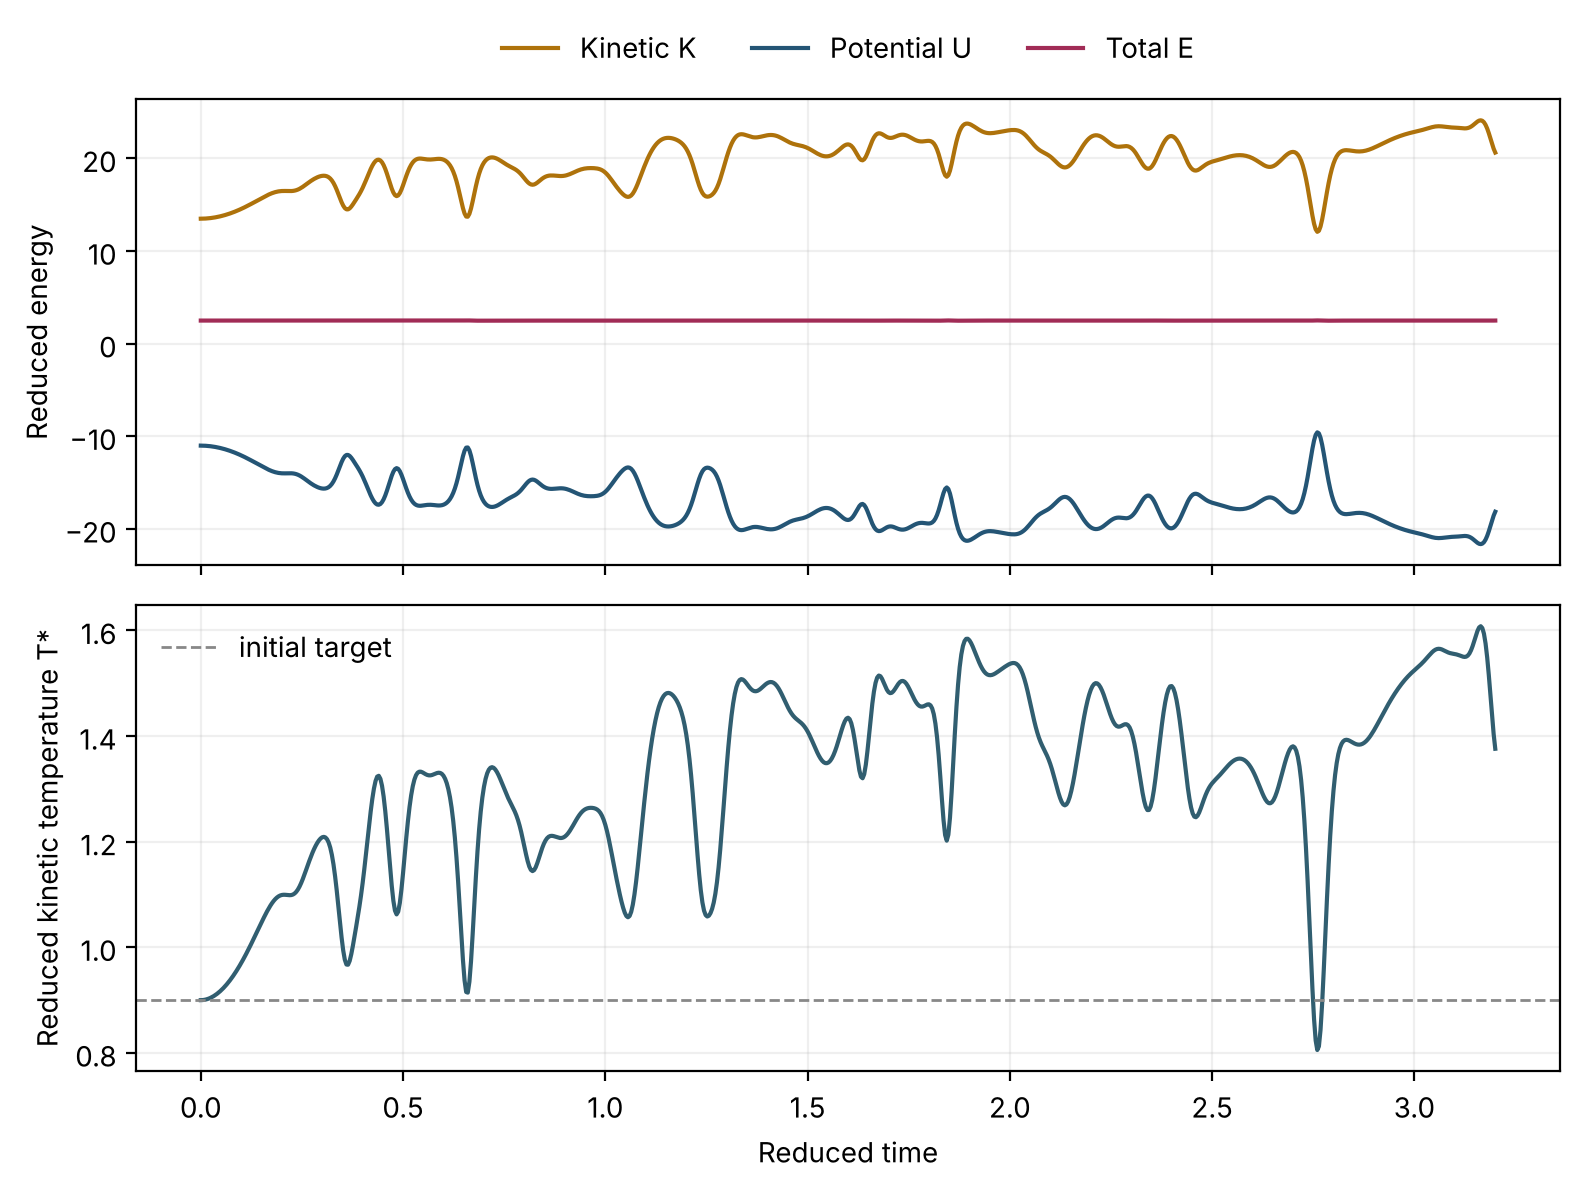

In [10]:
# Two stacked panels sharing the time axis.
fig, axes = plt.subplots(2, 1, figsize=(8.0, 6.0), sharex=True)
# Kinetic energy against time.
axes[0].plot(results['time'], results['kinetic'], label='Kinetic K', color='#ae720b')
# Potential energy against time.
axes[0].plot(results['time'], results['potential'], label='Potential U', color='#245575')
# Total energy against time: it should stay almost flat.
axes[0].plot(results['time'], results['total'], label='Total E', color='#a12c56')
# Label the upper panel's y-axis.
axes[0].set_ylabel('Reduced energy')
# Put the legend above the panel in three columns.
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, 1.20),
               ncol=3, frameon=False)
# Lower panel: kinetic temperature against time.
axes[1].plot(results['time'], results['temperature'], color='#315e70')
# Dashed line at the starting target temperature.
axes[1].axhline(initial_temperature, color='#888888', linestyle='--',
                linewidth=1, label='initial target')
# Axis labels for the lower panel.
axes[1].set(xlabel='Reduced time', ylabel='Reduced kinetic temperature T*')
# Legend without a box.
axes[1].legend(frameon=False)
# For both panels ...
for ax in axes:
    # ... add a faint grid.
    ax.grid(alpha=0.2)
# Tidy the layout.
fig.tight_layout()
# Display the figure.
plt.show()


## 7. Basic analysis of the generated data

We treat the second half of the run as an **illustrative analysis window**. This is a convenient teaching choice, not a proof that the system has equilibrated. Mean, sample standard deviation, minimum, and maximum summarize the recorded instantaneous kinetic temperatures. Consecutive MD samples are correlated, so their sample SD measures the spread in this time series; it is **not** automatically the uncertainty of the mean. We report mean $U/N$ and $K/N$ to compare energies per particle.

For a simple integration diagnostic, calculate

$$D=\frac{\max_t |E(t)-E(0)|}{\max(|E(0)|,1)}\times100\%.$$

This normalized maximum energy deviation is **not** an experimental error bar or a measure of temperature uncertainty. A nonzero value reflects numerical integration and, in our finite-cutoff model, a possible contribution from the discontinuity of the force at $r_c$. Its size should be examined when changing the time step.


In [11]:
# Index where the later half of the run begins.
window_start = len(results['time']) // 2
# Temperatures from the later half only (after the start-up transient).
later_temperature = results['temperature'][window_start:]
# Kinetic energies from the later half.
later_kinetic = results['kinetic'][window_start:]
# Potential energies from the later half.
later_potential = results['potential'][window_start:]
# Total energy at time 0, the reference for energy conservation.
energy_reference = results['total'][0]
# Largest departure of the total energy from its starting value.
max_energy_deviation = np.max(np.abs(results['total'] - energy_reference))
# As a percentage (max(..., 1.0) avoids dividing by a value near zero).
energy_deviation_percent = 100 * max_energy_deviation / max(abs(energy_reference), 1.0)

# Collect the results in a dictionary of named values.
summary = {
    'seed': results['seed'],
    'particles': particle_count,
    'steps': results['n_steps'],
    'mean_T_star': statistics.mean(later_temperature),
    'sample_SD_T_star': statistics.stdev(later_temperature),
    'minimum_T_star': min(later_temperature),
    'maximum_T_star': max(later_temperature),
    'mean_K_per_particle': statistics.mean(later_kinetic) / particle_count,
    'mean_U_per_particle': statistics.mean(later_potential) / particle_count,
    'max_energy_deviation_percent': energy_deviation_percent,
}
# Print each entry on its own line ...
for label, value in summary.items():
    # ... floats with 5 decimals, other values (integers) as they are.
    print(f'{label:30s} {value:.5f}' if isinstance(value, float)
          else f'{label:30s} {value}')


seed                           2026
particles                      16
steps                          800
mean_T_star                    1.40720
sample_SD_T_star               0.13141
minimum_T_star                 0.80551
maximum_T_star                 1.60809
mean_K_per_particle            1.31925
mean_U_per_particle            -1.16305
max_energy_deviation_percent   0.62124


The histogram below shows a distribution of instantaneous kinetic-temperature estimates in our chosen time window. It is a descriptive graph of one finite, correlated trajectory. Changing the number of bins changes its appearance. It should not be presented as a measured temperature distribution for a real material.


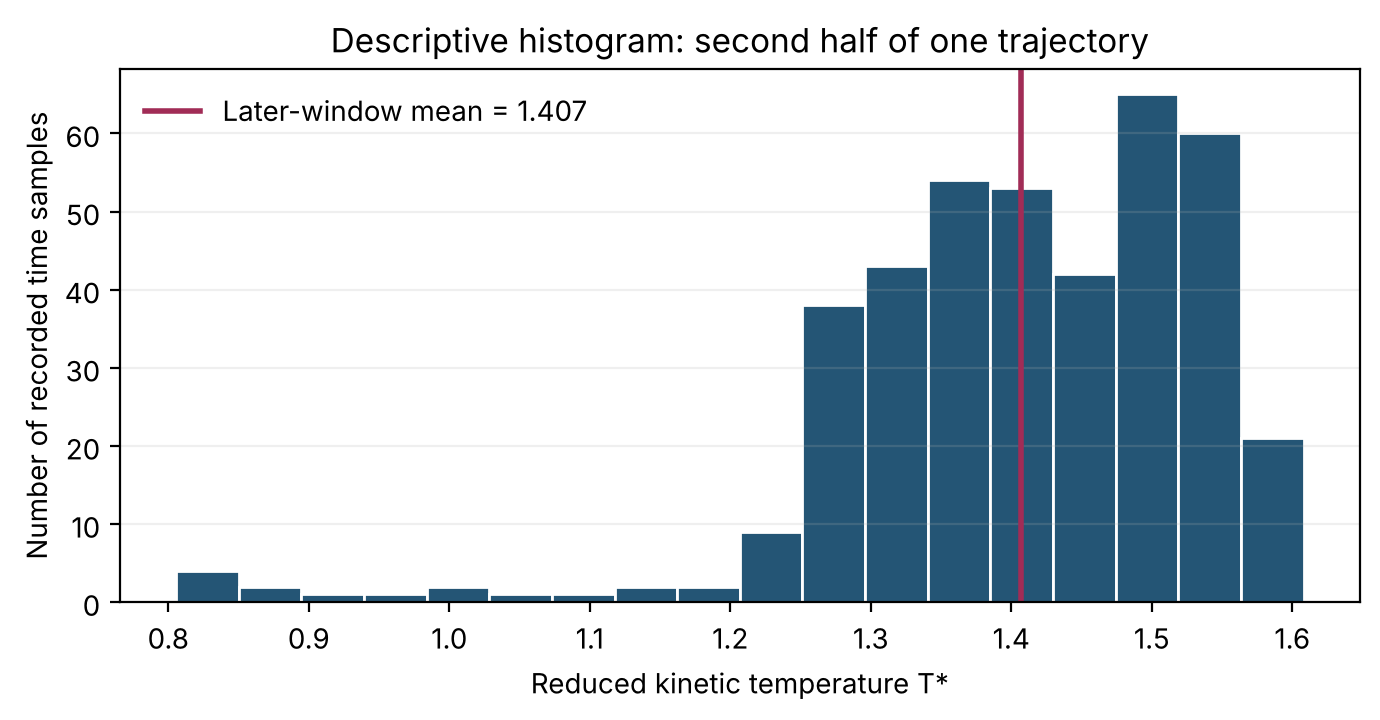

In [12]:
# Create a figure for the histogram.
fig, ax = plt.subplots(figsize=(7, 3.7))
# Histogram of the later-half temperatures in 18 bins.
ax.hist(later_temperature, bins=18, color='#245575', edgecolor='white')
# Mark the mean with a vertical line.
ax.axvline(summary['mean_T_star'], color='#a12c56', linewidth=2,
           label=f"Later-window mean = {summary['mean_T_star']:.3f}")
# Axis labels and title.
ax.set(xlabel='Reduced kinetic temperature T*',
       ylabel='Number of recorded time samples',
       title='Descriptive histogram: second half of one trajectory')
# Legend without a box.
ax.legend(frameon=False)
# Horizontal grid lines only.
ax.grid(axis='y', alpha=0.2)
# Tidy the layout.
fig.tight_layout()
# Display the figure.
plt.show()


## 8. Check reproducibility and a physical invariant

The first test reruns the model with the same seed and settings. A separate NumPy generator is created inside each call, so the complete temperature histories should match. The second test checks the total force at a displaced configuration: internal pair forces must sum to (approximately) zero because of Newton's third law. These are useful **code checks**; they do not prove that the physical model represents a real fluid.


In [13]:
# Run again with exactly the same seed and settings.
repeat = run_md(seed=2026, time_step=0.004, n_steps=800)
# True only if every recorded temperature is identical.
same_history = np.array_equal(results['temperature'], repeat['temperature'])
# Final positions of the first run.
test_positions = results['snapshots'][results['n_steps']]
# Recompute the forces at those positions.
test_forces, _ = forces_and_potential(test_positions, box_length)
# Length of the total force vector: should be zero up to round-off.
net_force_norm = np.linalg.norm(test_forces.sum(axis=0))

# Report the reproducibility test.
print('Identical complete temperature history:', same_history)
# Report the net-force check in scientific notation.
print('Norm of net internal force:', f'{net_force_norm:.3e}')
# Stop with an error if the runs differ.
assert same_history
# Stop with an error if the forces do not cancel.
assert net_force_norm < 1e-10


Identical complete temperature history: True
Norm of net internal force: 6.951e-15


## 9. Guided questions and small experiments

1. **Trace a variable.** What is the shape of `starting_positions`? What does `starting_positions[3]` represent? Why is `len(results['time'])` one greater than `n_steps`?
2. **Trace a loop.** How many distinct pairs does `forces_and_potential` inspect for 16 particles? Use $N(N-1)/2$ to check your answer. Why does its inner loop start at `i + 1`?
3. **Explain a conditional.** What error does the `if distance_squared < 0.09` statement catch? Would removing it improve the physics?
4. **Interpret the graph.** Does a rise in kinetic energy require a rise in total energy? Point to a segment of the energy graph that supports your answer.
5. **Change the seed.** Run `alternate = run_md(seed=2027)`. Compare its later-window mean temperature with `summary['mean_T_star']`. Does a seed change the interaction law, or only the starting velocities?
6. **Change the time step.** Try `coarser = run_md(seed=2026, time_step=0.008, n_steps=400)`, which keeps approximately the same final time. Compare the maximum energy deviation with the baseline. A numerical trend in one run is a diagnostic, not a universal guarantee.

Run the following optional code cell to begin Questions 5 and 6. It does not change the original `results` dictionary.


In [14]:
# Same settings, different random velocities.
alternate = run_md(seed=2027)
# Twice the time step and half the steps: same final time (3.2), coarser integration.
coarser = run_md(seed=2026, time_step=0.008, n_steps=400)

# Define a helper for the largest energy deviation of a run, in percent.
def max_deviation_percent(data):
    # The run's starting total energy.
    reference = data['total'][0]
    # Largest departure, as a percentage of the starting value.
    return (100 * np.max(np.abs(data['total'] - reference))
            / max(abs(reference), 1.0))

# Later-half mean temperature of the baseline run.
print('Baseline mean T*, later half: ', f"{summary['mean_T_star']:.3f}")
# The same quantity for the new seed.
print('New seed mean T*, later half:',
      f"{statistics.mean(alternate['temperature'][len(alternate['time'])//2:]):.3f}")
# Energy conservation with dt = 0.004.
print('Baseline max E deviation (%):', f'{max_deviation_percent(results):.4f}')
# Energy conservation with dt = 0.008: expect a larger deviation.
print('Coarser max E deviation (%): ', f'{max_deviation_percent(coarser):.4f}')


Baseline mean T*, later half:  1.407
New seed mean T*, later half: 1.346
Baseline max E deviation (%): 0.6212
Coarser max E deviation (%):  2.5788


In this example, changing the seed changes the later-window mean even though the force law is unchanged. Doubling the time step produces a larger energy deviation over approximately the same duration. One comparison is a useful diagnostic, but a careful numerical study would examine more time steps and longer trajectories.


## 10. What this model does and does not show

This exercise uses identical, structureless particles in two spatial dimensions, periodic boundaries, a simple pair force, and a small number of steps. Its density is per **area**, and the kinetic-temperature formula is specific to 2D. There is no thermostat, no pressure calculation, no chemical detail, and no calibration to a particular substance. The short trajectory and an arbitrary later-window average do not establish equilibrium, independent samples, or a physical phase. Total-energy monitoring and reproducibility checks address implementation quality, not experimental validity.

For further reading, consult the official [LAMMPS Lennard-Jones potential documentation](https://docs.lammps.org/pair_lj.html), its [velocity-Verlet NVE integrator documentation](https://docs.lammps.org/fix_nve.html), and the [GROMACS discussion of kinetic temperature and removed centre-of-mass degrees of freedom](https://manual.gromacs.org/documentation/2026.0/reference-manual/algorithms/molecular-dynamics.html). Professional MD packages offer many additional features. Our 2D, finite-cutoff implementation and its unit convention are specified above so that every calculation remains visible to a beginning programmer.
